# 01. Data Exploration & Stratified Partitioning

**Course**: CS 328 — Introduction to Data Science  
**Project**: *Does Graph-Based Retrieval Beat Vector Search on Multi-Hop Questions?*  
**Phase 1**: Exploring 2WikiMultiHopQA dataset, checking question types, verifying disjoint splits, and inspecting symmetric passage representations.

In [1]:
import sys
from pathlib import Path
# Add project root to sys.path
sys.path.insert(0, str(Path.cwd().parent))

from src import config
from src.data_loader import get_or_create_splits, normalize_text, normalize_answer
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the pre-registered disjoint splits
eval_split, tune_split = get_or_create_splits()
print(eval_split.summary())
print("" + tune_split.summary())

2026-11-11 23:31:34,445 [INFO] Found existing serialized splits. Loading directly...
2026-11-11 23:31:34,446 [INFO] Loading split from /Users/hemcharanvarma/Desktop/ids_project/data/2wikimultihopqa/eval_split.json...
2026-11-11 23:31:34,478 [INFO] Loading split from /Users/hemcharanvarma/Desktop/ids_project/data/2wikimultihopqa/tune_split.json...


=== DatasetSplit: EVAL ===
Total Questions: 200
Unique Passages in Corpus: 1484
Stratification Breakdown:
  - compositional     :  83 ( 41.5%)
  - inference         :  25 ( 12.5%)
  - comparison        :  48 ( 24.0%)
  - bridge_comparison :  44 ( 22.0%)
Avg Gold Passages/Question: 2.44
=== DatasetSplit: TUNE ===
Total Questions: 100
Unique Passages in Corpus: 800
Stratification Breakdown:
  - compositional     :  42 ( 42.0%)
  - inference         :  12 ( 12.0%)
  - comparison        :  24 ( 24.0%)
  - bridge_comparison :  22 ( 22.0%)
Avg Gold Passages/Question: 2.44


## 1. Verify Zero Data Snooping (Disjoint Splits Invariant)

In [2]:
overlap = eval_split.question_ids.intersection(tune_split.question_ids)
print(f"Question overlap count: {len(overlap)}")
assert len(overlap) == 0, "Splits must have zero overlap!"

Question overlap count: 0


## 2. Question Types Distribution (Stratification Analysis)

Evaluation Split Type Counts:
type
compositional        83
comparison           48
bridge_comparison    44
inference            25
Name: count, dtype: int64


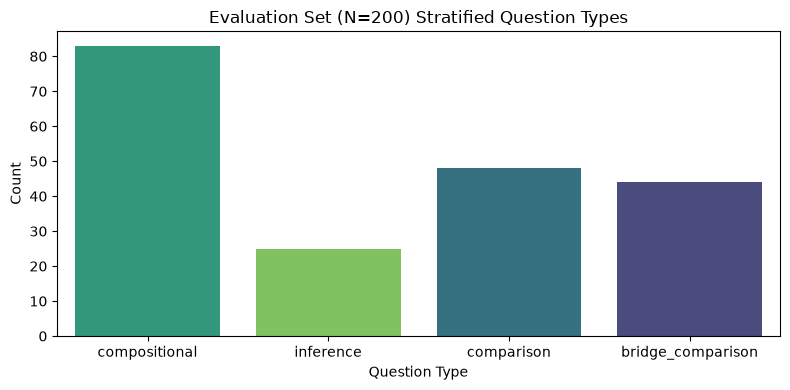

In [3]:
eval_df = pd.DataFrame([{
    "id": q.id,
    "type": q.type,
    "question": q.question,
    "answer": q.answer,
    "gold_count": len(q.gold_titles),
    "context_count": len(q.context_titles)
} for q in eval_split.questions])

print("Evaluation Split Type Counts:")
print(eval_df["type"].value_counts())

# Plot question type distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=eval_df, x="type", hue="type", order=config.QUESTION_TYPES, palette="viridis", legend=False)
plt.title("Evaluation Set (N=200) Stratified Question Types")
plt.xlabel("Question Type")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("../figures/question_types_distribution.png", dpi=150)
plt.show()

## 3. Sample Questions & Symmetric Passage Representation

In [4]:
for qtype in config.QUESTION_TYPES:
    sample = eval_split.filter_by_type(qtype)[0]
    print(f"=== [{qtype.upper()}] ===")
    print(f"Q: {sample.question}")
    print(f"A: {sample.answer}")
    print(f"Gold Titles: {sample.gold_titles}")
    first_gold = next(iter(sample.gold_titles))
    p = eval_split.get_passage(first_gold)
    if p:
        print(f"Passage Snippet:{p.full_text[:180]}...")

=== [COMPOSITIONAL] ===
Q: Where did Athenais Philostorgos Ii's mother die?
A: Pharnacia
Gold Titles: {'monime', 'athenais philostorgos ii'}
Passage Snippet:Title: Monime
Text: Monime, sometimes known as Monima (died 72/71 BC), was a Greek Macedonian noblewoman from Anatolia and one of the wives of King Mithridates VI of Pontus. Accord...
=== [INFERENCE] ===
Q: Who is the paternal grandmother of Edward I Of England?
A: Isabella of Angoulême
Gold Titles: {'edward i of england', 'henry iii of england'}
Passage Snippet:Title: Edward I of England
Text: Edward I (17/18 June 1239 – 7 July 1307), also known as Edward Longshanks and the Hammer of the Scots , was King of England from 1272 to 1307. Befo...
=== [COMPARISON] ===
Q: Was Emmy Drachmann or Joseph-Émile Dubreuil born first?
A: Emmy Drachmann
Gold Titles: {'emmy drachmann', 'joseph-émile dubreuil'}
Passage Snippet:Title: Emmy Drachmann
Text: " Emmy Drachmann"( 23 October 1854 – 20 January 1928) was a Danish writer and the wife of Holge